# 03 - Identificação de Features

Objetivo: ranquear atributos por correlação e mutual information, avaliar categorias por taxa de fraude e registrar o conjunto recomendado para o modelo.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.features.selection import (
    correlation_with_target,
    encode_for_scoring,
    feature_matrix,
    fraud_rate_by_category,
    mutual_information_scores,
    rank_features,
)

PROCESSED_PATH = ROOT / "data" / "processed" / "transactions_clean.csv"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

## Base processada

In [2]:
df = pd.read_csv(PROCESSED_PATH)
X, y = feature_matrix(df)
print(df.shape)
print("Features candidatas:", list(X.columns))
print("Taxa de fraude:", f"{y.mean():.2%}")

(299695, 20)
Features candidatas: ['account_age_days', 'total_transactions_user', 'avg_amount_user', 'amount', 'country', 'bin_country', 'channel', 'merchant_category', 'promo_used', 'avs_match', 'cvv_result', 'three_ds_flag', 'shipping_distance_km', 'hour', 'day_of_week', 'is_night', 'country_bin_mismatch', 'amount_to_avg_ratio']
Taxa de fraude: 2.21%


## Taxa de fraude por categoria

In [3]:
for col in ["channel", "merchant_category", "country", "bin_country"]:
    print(f"\n=== {col} ===")
    display(fraud_rate_by_category(df, col))


=== channel ===


,n,fraud_rate
channel,,
web,152226,0.0356
app,147469,0.0080



=== merchant_category ===


,n,fraud_rate
merchant_category,,
travel,59922,0.0232
electronics,60220,0.0225
fashion,59801,0.0224
gaming,59839,0.0216
grocery,59913,0.0206



=== country ===


,n,fraud_rate
country,,
TR,30074,0.0280
RO,29501,0.0240
PL,29965,0.0234
ES,28885,0.0231
US,32430,0.0231
FR,30343,0.0219
IT,28615,0.0212
GB,30602,0.0212
NL,30220,0.0178



=== bin_country ===


,n,fraud_rate
bin_country,,
TR,29972,0.0261
PL,29963,0.0233
RO,29532,0.0230
ES,29058,0.0229
IT,28709,0.0223
US,32295,0.0220
GB,30563,0.0218
FR,30261,0.0216
NL,30256,0.0196


## Correlação (numéricas)

,corr_with_is_fraud
amount_to_avg_ratio,0.292384
shipping_distance_km,0.270004
avs_match,-0.223299
cvv_result,-0.218982
amount,0.202499
country_bin_mismatch,0.181083
three_ds_flag,-0.162160
account_age_days,-0.120340
promo_used,0.067351
total_transactions_user,-0.017093


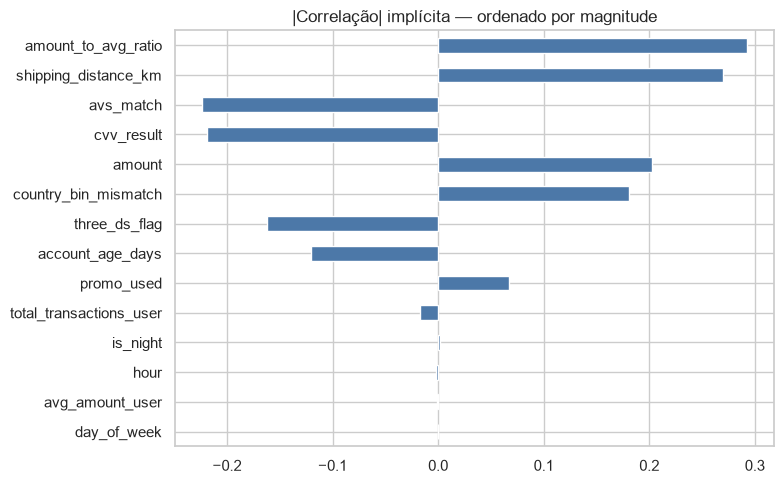

In [4]:
corr = correlation_with_target(df)
display(corr.to_frame("corr_with_is_fraud"))

ax = corr.plot(kind="barh", figsize=(8, 5), color="#4C78A8")
ax.set_title("|Correlação| implícita - ordenado por magnitude")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_correlation_features.png", dpi=120)
plt.show()

## Mutual information (com one-hot das categóricas)

,mutual_info
avs_match,0.077199
three_ds_flag,0.072624
cvv_result,0.071453
channel_web,0.051916
channel_app,0.051655
amount_to_avg_ratio,0.035901
amount,0.030303
account_age_days,0.030209
shipping_distance_km,0.029338
avg_amount_user,0.028449


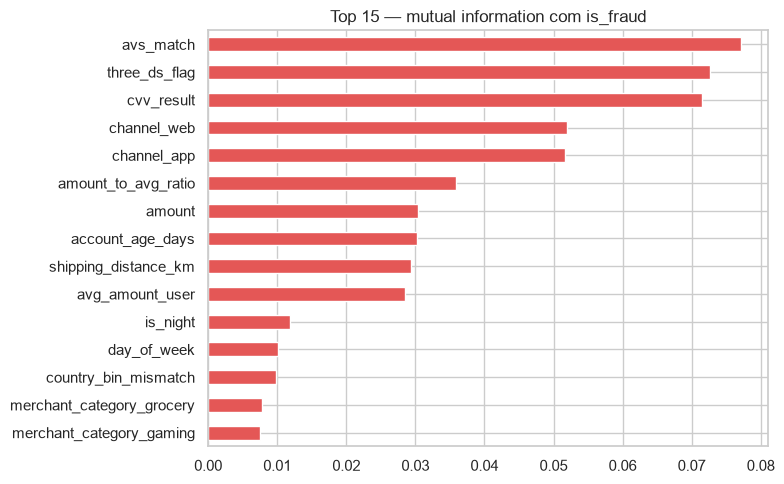

In [5]:
X_enc = encode_for_scoring(X)
mi = mutual_information_scores(X_enc, y)
display(mi.head(20).to_frame())

ax = mi.head(15).sort_values().plot(kind="barh", figsize=(8, 5), color="#E45756")
ax.set_title("Top 15 - mutual information com is_fraud")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_mutual_information.png", dpi=120)
plt.show()

## Ranking combinado

In [6]:
ranking = rank_features(df)
display(ranking.head(20))
ranking.to_csv(ROOT / "reports" / "feature_ranking.csv")
print("Ranking salvo em reports/feature_ranking.csv")

,mutual_info,abs_corr
avs_match,0.077199,0.223299
three_ds_flag,0.072624,0.162160
cvv_result,0.071453,0.218982
channel_web,0.051916,NaN
channel_app,0.051655,NaN
amount_to_avg_ratio,0.035901,0.292384
amount,0.030303,0.202499
account_age_days,0.030209,0.120340
shipping_distance_km,0.029338,0.270004
avg_amount_user,0.028449,0.001236


Ranking salvo em reports/feature_ranking.csv


## Conclusão - features recomendadas

### Prioridade alta (manter)
- `amount_to_avg_ratio`, `shipping_distance_km`, `amount`
- `avs_match`, `cvv_result`, `three_ds_flag`, `country_bin_mismatch`
- `account_age_days`, `promo_used`
- `channel` (web concentra mais fraude que app)

### Prioridade média
- `hour` / `day_of_week` / `is_night` (sinal temporal fraco isoladamente, mas barato de manter)
- `merchant_category`, `country`, `bin_country` (efeito menor que o mismatch; one-hot)
- `total_transactions_user`, `avg_amount_user` (perfil do usuário; `avg` já entra na razão)

### Remover / não usar como feature
- `transaction_id`, `user_id` - identificadores
- `transaction_time` bruto - substituído por campos de calendário

Observação: a seleção aqui é **exploratória**. No treino do modelo, o ranking deve ser reestimado **apenas no conjunto de treino** para evitar vazamento.